# Project 2 — Sentiment Analysis
## Part 1: Initial Data Analysis (EDA)

This notebook explores the Amazon electronics reviews dataset and connects each result to decisions that may be useful in the later sentiment-modeling stage.

For every question, the notebook includes:
- the requested analysis and its output;
- a **presentation block** explaining what the result tells us;
- a **modeling connection** describing how the finding may influence later experiments.

The analysis uses the training dataset and the product metadata mapping file. The conclusions below are based on the outputs generated in this notebook; where an interpretation is only a hypothesis, it is identified as something to test rather than a proven fact.

## 0. Imports and load the data

In [20]:
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS


DATA_PATH = "train_data.csv"          
PRODUCTS_PATH = "title_brand.csv"    

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
print("\\nColumns:")
print(df.columns.tolist())
display(df.head())

required_for_project = {"reviewText", "reviewerID", "vote", "asin"}
missing = required_for_project - set(df.columns)
if missing:
    print("Warning: columns needed for some analyses are missing:", sorted(missing))


C:\Users\BiaDigi.com\AppData\Local\Temp\ipykernel_4056\619633782.py:12: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(DATA_PATH)


Dataset shape: (838944, 11)
\nColumns:
['overall', 'vote', 'verified', 'reviewTime', 'reviewerID', 'asin', 'style', 'reviewerName', 'reviewText', 'summary', 'unixReviewTime']


,overall,vote,verified,reviewTime,reviewerID,asin,style,reviewerName,reviewText,summary,unixReviewTime
0,2,NaN,False,2016-11-11,A2OSUEZJIN7BI,0511189877,NaN,Chris,I have an older URC-WR7 remote and thought thi...,Cannot Learn,1478822400
1,5,NaN,True,2016-06-06,A2NETQRG6JHIG7,0511189877,NaN,Qrysta White,First time I've EVER had a remote that needed ...,zero programming needed! Miracle!?,1465171200
2,4,NaN,True,2016-03-10,A12JHGROAX49G7,0511189877,NaN,Linwood,Got them and only 2 of them worked. company ca...,Works Good and programs easy.,1457568000
3,5,NaN,True,2016-01-14,A1KV65E2TMMG6F,0511189877,NaN,Dane Williams,I got tired of the remote being on the wrong s...,Same as TWC remote,1452729600
4,5,NaN,True,2016-10-20,A280POPEWI0NSA,0594459451,NaN,Kristina H.,After purchasing cheap cords from another webs...,Good Quality Cord,1476921600


In [21]:
df['overall'].isna().sum()

np.int64(0)

## Question 1 — Distribution of `overall`

We first examine the target variable: the product rating (`overall`, from 1 to 5). The distribution helps us determine whether some ratings are much more common than others and whether class imbalance should be considered during model training.

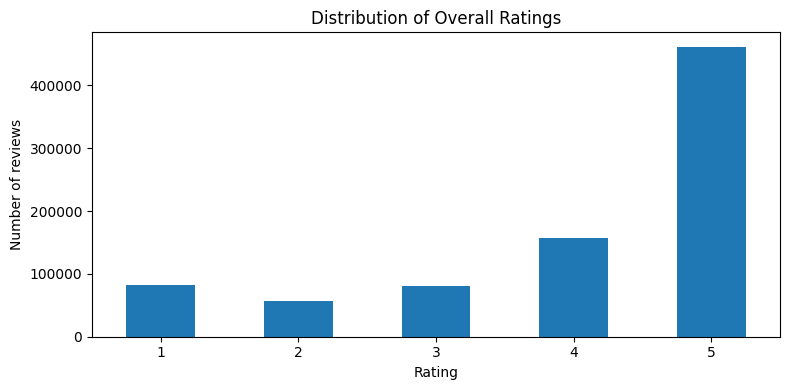

,count,percentage
overall,,
1,82950,9.89
2,56756,6.77
3,81239,9.68
4,156514,18.66
5,461485,55.01


Max/min non-zero class count ratio: 8.13
Interpretation: one rating class contains more than half of all reviews; the distribution is notably imbalanced.


In [22]:
if "overall" in df.columns:
    ratings = pd.to_numeric(df["overall"], errors="coerce").dropna()
    rating_counts = ratings.value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)

    ax = rating_counts.plot(kind="bar", figsize=(8, 4), rot=0)
    ax.set_title("Distribution of Overall Ratings")
    ax.set_xlabel("Rating")
    ax.set_ylabel("Number of reviews")
    plt.tight_layout()
    plt.show()

    rating_share = (rating_counts / rating_counts.sum() * 100).round(2)
    display(pd.DataFrame({
        "count": rating_counts,
        "percentage": rating_share
    }))

    imbalance_ratio = rating_counts.max() / rating_counts[rating_counts > 0].min()
    print(f"Max/min non-zero class count ratio: {imbalance_ratio:.2f}")
    if rating_counts.eq(0).any():
        print("At least one rating class is absent in this file.")
    elif rating_counts.max() / rating_counts.sum() > 0.50:
        print("Interpretation: one rating class contains more than half of all reviews; the distribution is notably imbalanced.")
    else:
        print("Interpretation: check the counts/percentages above to judge the degree of imbalance.")


### What does the rating distribution tell us?

The rating distribution is clearly imbalanced. Rating 5 accounts for approximately **55.01%** of all reviews, while rating 2 accounts for only **6.77%**. The most frequent class is therefore about **8.13 times** as large as the least frequent class. Ratings 4 and 5 together make up approximately **73.67%** of the dataset, so positive reviews dominate the training data.

This imbalance matters because a model trained on the original distribution may become better at predicting common ratings than less frequent ones. However, imbalance does not automatically mean that we should change the dataset.

**Possible solutions**
1. **Undersampling:** reduce the number of examples in the majority class. This can discard useful review text, which is undesirable when we have a large but valuable text dataset.
2. **Oversampling:** increase the representation of minority classes, for example by randomly repeating their training examples. This keeps more majority-class information but can cause the model to overfit repeated examples.
3. **Class weighting:** assign larger loss weights to less frequent classes. This keeps the original examples and is a sensible first experiment for this project.

**Decision for the modeling stage:** keep the original data as the baseline, use a stratified train/validation split, and compare an ordinary model with a class-weighted model. We should choose based on validation results, especially per-class recall and macro F1, while also tracking the project's official **micro F1** metric. Since this is single-label classification, micro F1 is equivalent to accuracy.

*Presentation takeaway:* “Our dataset is not balanced: more than half of the reviews have five stars. Instead of immediately deleting or duplicating data, we will first preserve the original distribution and test whether class weighting improves predictions for the less frequent ratings.”

## Question 2 — Word clouds for positive, neutral, and negative reviews

For this analysis, reviews are grouped according to the assignment:
- **Positive:** ratings 4 or 5
- **Neutral:** rating 3
- **Negative:** ratings 1 or 2

The word clouds show the most frequent words in each group. They are useful for exploration, but word size represents frequency, not how strongly a word predicts sentiment.

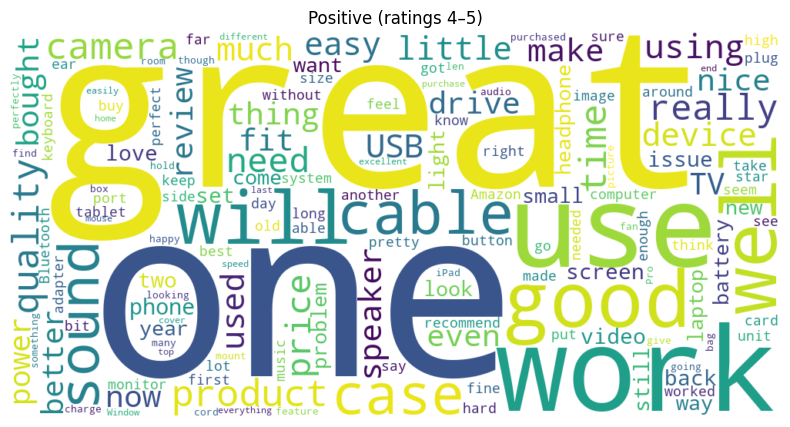

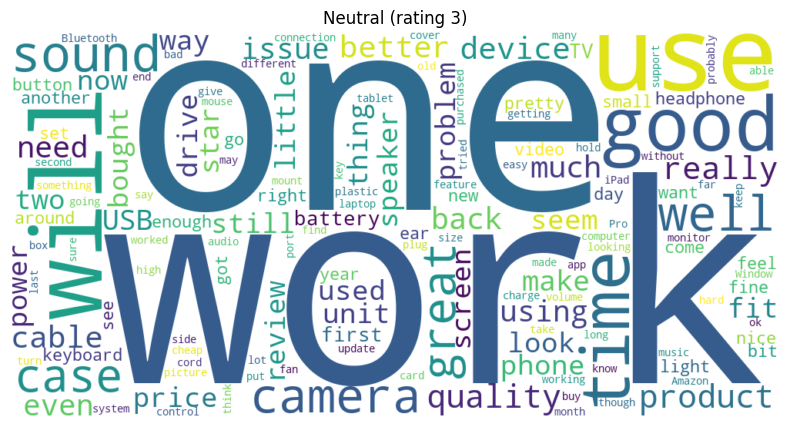

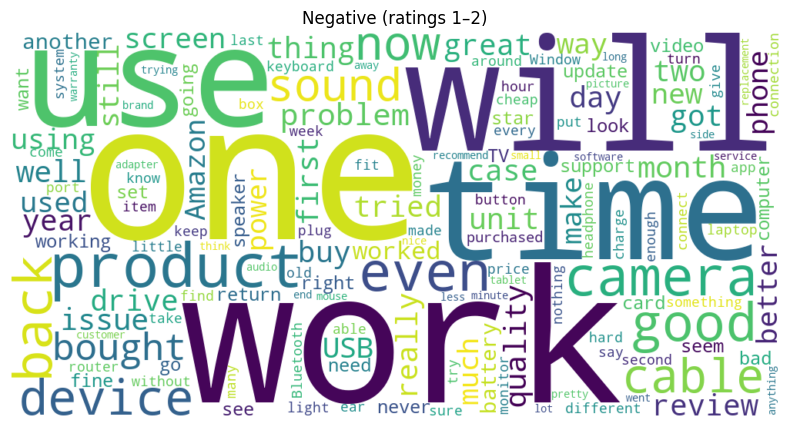

Interpretation guide: compare the positive and negative clouds for shared words. A shared word may be product-specific (for example, a device name) or may be used in different contexts. Read representative reviews before drawing conclusions.


In [23]:
if "overall" in df.columns and "reviewText" in df.columns:

    word_df = df[["overall", "reviewText"]].copy()
    word_df["overall"] = pd.to_numeric(word_df["overall"], errors="coerce")
    word_df["reviewText"] = word_df["reviewText"].fillna("").astype(str)

    sentiment_groups = {
        "Positive (ratings 4–5)": word_df[word_df["overall"].isin([4, 5])],
        "Neutral (rating 3)": word_df[word_df["overall"].eq(3)],
        "Negative (ratings 1–2)": word_df[word_df["overall"].isin([1, 2])]
    }

    for title, group in sentiment_groups.items():
        text = " ".join(group["reviewText"].tolist()).strip()
        if not text:
            print(f"No review text available for {title}.")
            continue
        cloud = WordCloud(
            width=1000,
            height=500,
            background_color="white",
            stopwords=STOPWORDS,
            collocations=False,
            max_words=150
        ).generate(text)

        plt.figure(figsize=(12, 5))
        plt.imshow(cloud, interpolation="bilinear")
        plt.axis("off")
        plt.title(title)
        plt.show()

    print(
        "Interpretation guide: compare the positive and negative clouds for shared words. "
        "A shared word may be product-specific (for example, a device name) or may be used "
        "in different contexts. Read representative reviews before drawing conclusions."
    )
else:
    print("Skipped: Question 2 needs both 'overall' and 'reviewText'. Use the full training CSV.")


### What do the word clouds tell us?

The three clouds share several frequent words. In the positive cloud, words such as **good, great, easy, work, well, love, quality,** and **cable** are prominent. In the neutral cloud, we see words such as **one, use, work, good, well, sound, quality, camera, price,** and **issue**. In the negative cloud, **work, one, use, product, cable, device, tried, problem, return,** and **quality** appear frequently.

There are two useful observations:

**1. Some words are common across different sentiment groups.**  
Words such as `work`, `use`, `good`, `quality`, `cable`, and `device` appear in more than one cloud. This is expected: customers discuss the same product features whether they are satisfied or dissatisfied. For example:
- “The device works perfectly.”
- “The device does not work.”

The word `work` appears in both sentences, but the sentiment is different. Therefore, the presence of a single word is not enough to determine sentiment.

**2. Context and negation are important.**  
Words such as `not`, `never`, and `no` can reverse the meaning of a phrase. A preprocessing step that removes these words could damage sentiment information. Neutral reviews also contain a mixture of positive- and negative-sounding vocabulary, which suggests that a three-star review may describe both advantages and problems.

**What this means for modeling**
- Do not remove shared words just because they occur in both positive and negative reviews.
- Preserve negation words such as `not`, `never`, and `no`.
- Try word-level **unigrams and bigrams** together. Phrases such as `not good` and `does not work` can carry more information than isolated words.
- Consider a carefully reviewed custom stop-word list for exploratory word clouds. Do not automatically remove every frequent word from model input: words such as `use` or `work` may still be useful in context.
- Later, use validation results to decide whether stemming, lemmatization, or other text preprocessing actually helps.

*Presentation takeaway:* “The clouds show that customers discuss many of the same product features in all three sentiment groups. This tells us that sentiment depends on context and negation, not simply on whether a word is present. That is why we will preserve negations and test TF-IDF with both single words and two-word phrases.”

## Question 3 — Top 10 reviewers by total helpful votes

In [24]:
if {"reviewerID", "vote"}.issubset(df.columns):
    votes = df.copy()
    votes["vote"] = pd.to_numeric(votes["vote"], errors="coerce").fillna(0)

    if "reviewerName" in votes.columns:
        reviewer_totals = (
            votes.groupby("reviewerID", dropna=False)
            .agg(
                total_vote=("vote", "sum"),
                reviewer_name=("reviewerName", lambda s: s.dropna().iloc[0] if not s.dropna().empty else "Unknown"),
                review_count=("reviewerID", "size")
            )
            .sort_values("total_vote", ascending=False)
            .head(10)
            .reset_index()
        )
        reviewer_totals = reviewer_totals[["reviewer_name", "reviewerID", "total_vote", "review_count"]]
    else:
        reviewer_totals = (
            votes.groupby("reviewerID", dropna=False)
            .agg(total_vote=("vote", "sum"), review_count=("reviewerID", "size"))
            .sort_values("total_vote", ascending=False)
            .head(10)
            .reset_index()
        )

    display(reviewer_totals)


,reviewer_name,reviewerID,total_vote,review_count
0,Benson Leung,A25GROL6KJV3QG,4572.0,29
1,Obi Wan,A2IK776FY6MEMG,1608.0,29
2,Chris Winter,A1A39899KH5QCI,1352.0,4
3,Mayra S.,AMYCUX8EWEUVV,1342.0,19
4,VermontGuy,A9K7V1MKJ9BOJ,1337.0,7
5,Michael,A1UQUDT2Q0YENM,1230.0,132
6,PhotoGraphics,A3R1WFO4KIUQXZ,1209.0,68
7,Nicholas,A2Z9APP5B09MFY,1188.0,23
8,NLee the Engineer,AOEAD7DPLZE53,1103.0,31
9,David H,AZPCDY9OQ605E,1045.0,5


### What do the reviewer results tell us?

The top reviewer, **Benson Leung**, has **4,572 helpful votes across 29 reviews**. Other examples show that a high total does not necessarily require a large number of reviews: Chris Winter has 1,352 votes from 4 reviews, and David H has 1,045 votes from 5 reviews. By comparison, Michael has 1,230 votes across 132 reviews.

This suggests that helpful votes are not simply a measure of how many reviews someone writes. A small number of reviews can receive substantial attention from other customers.

**What this means for modeling**

Helpful votes measure how useful other users found a review; they do not directly measure whether the review is positive or negative. A critical review can be very helpful, just as a positive review can be helpful. Vote counts may also be influenced by how long a review has been available.

For the main sentiment model, the required and most meaningful input remains `reviewText`. We should not treat `reviewerID` or `reviewerName` as sentiment features: they identify the author rather than describe the opinion, and may encourage the model to memorize user-specific patterns. The `vote` column could be investigated in a separate experiment only if it is available at prediction time and does not introduce information leakage.

*Presentation takeaway:* “Some users receive many helpful votes even from a small number of reviews. However, helpfulness is different from sentiment, so reviewer identity and vote count will not be part of our initial text-based sentiment model.”

## Question 4 — Histogram of review-text character lengths


count    838944.000000
mean        624.687384
std         684.129474
min         200.000000
1%          202.000000
5%          212.000000
50%         408.000000
95%        1733.000000
99%        3399.000000
max       29146.000000
Name: reviewText, dtype: float64


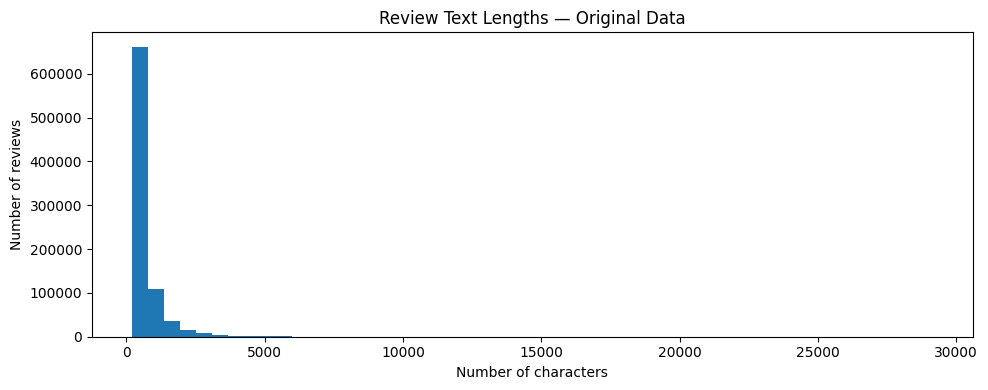

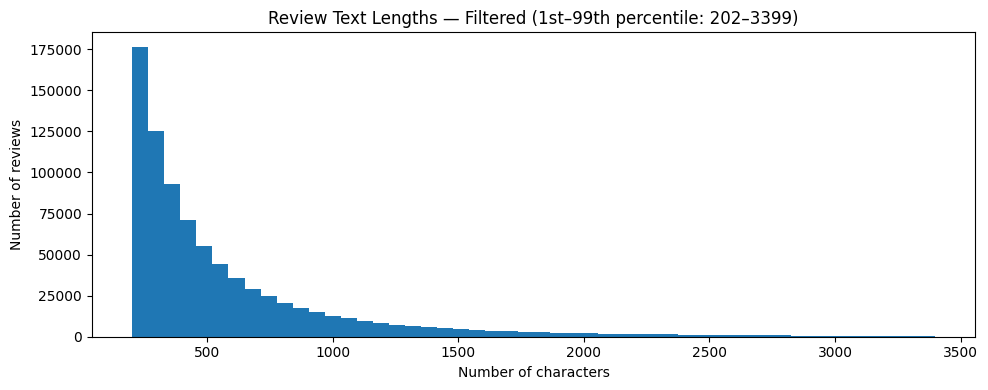

Rows before filtering: 838,944
Rows after filtering:  823,902
Rows excluded:         15,042
Interpretation: use the plots and percentiles to choose a practical range. A length limit can reduce computation, but should be justified and validated because very long or very short reviews may contain useful information.


In [25]:
if "reviewText" in df.columns:
    text_lengths = df["reviewText"].fillna("").astype(str).str.len()
    print(text_lengths.describe(percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]))

    plt.figure(figsize=(10, 4))
    plt.hist(text_lengths, bins=50)
    plt.title("Review Text Lengths — Original Data")
    plt.xlabel("Number of characters")
    plt.ylabel("Number of reviews")
    plt.tight_layout()
    plt.show()

    lower = text_lengths.quantile(0.01)
    upper = text_lengths.quantile(0.99)
    filtered_lengths = text_lengths[(text_lengths >= lower) & (text_lengths <= upper)]

    plt.figure(figsize=(10, 4))
    plt.hist(filtered_lengths, bins=50)
    plt.title(f"Review Text Lengths — Filtered (1st–99th percentile: {lower:.0f}–{upper:.0f})")
    plt.xlabel("Number of characters")
    plt.ylabel("Number of reviews")
    plt.tight_layout()
    plt.show()

    print(f"Rows before filtering: {len(text_lengths):,}")
    print(f"Rows after filtering:  {len(filtered_lengths):,}")
    print(f"Rows excluded:         {len(text_lengths) - len(filtered_lengths):,}")
    print(
        "Interpretation: use the plots and percentiles to choose a practical range. "
        "A length limit can reduce computation, but should be justified and validated "
        "because very long or very short reviews may contain useful information."
    )


### What does review length tell us?

The character-length distribution is strongly right-skewed:
- Median: **408 characters**
- Mean: **about 625 characters**
- 95th percentile: **1,733 characters**
- 99th percentile: **3,399 characters**
- Maximum: **29,146 characters**

Because the mean is larger than the median, a relatively small number of long reviews pull the average upward. The maximum is also far above the 99th percentile, showing that a small number of reviews are exceptionally long.

The percentile filter keeps **823,902 of 838,944 reviews** and excludes **15,042**, or about **1.79%**. This is useful for visualizing the central part of the distribution, but it does not mean those rows should automatically be deleted from the modeling dataset.

**What this means for modeling**

Very long reviews can increase memory use and training time. A possible solution is to set a maximum input length and truncate text beyond that limit. Based on this distribution, **1,733 characters (95th percentile)** and **3,399 characters (99th percentile)** are reasonable candidate limits to compare experimentally.

We should not choose one limit solely from the histogram. Train the same model with the original text and with one or both truncation limits, then compare validation performance and runtime. Also remember that character limits are not the same as token limits; transformer models generally impose limits in tokens.

*Presentation takeaway:* “Most reviews are much shorter than the longest examples. Rather than deleting long reviews and losing their information, we will test truncating them at candidate limits around the 95th and 99th percentiles and compare the validation results.”

## Question 5 — Top 10 products by number of five-star reviews

In [26]:
if True:
    products = pd.read_csv(PRODUCTS_PATH)
    print("Product mapping columns:", products.columns.tolist())

    def find_column(columns, candidates):
        lower_map = {str(c).strip().lower(): c for c in columns}
        for candidate in candidates:
            if candidate.lower() in lower_map:
                return lower_map[candidate.lower()]
        return None

    id_col = find_column(products.columns, ["asin", "product_id", "productid", "id"])
    title_col = find_column(products.columns, ["title", "product_title", "product title", "name"])
    brand_col = find_column(products.columns, ["brand", "brand_name", "brand name"])

    if id_col is None or title_col is None or brand_col is None:
        print("Could not identify product ID, title, and brand columns automatically.")
        print("Set id_col, title_col, and brand_col in this cell to match your mapping file.")
    else:
        five_star = df[pd.to_numeric(df["overall"], errors="coerce").eq(5)]
        counts = five_star.groupby("asin").size().rename("five_star_review_count").reset_index()
        product_table = counts.merge(
            products[[id_col, title_col, brand_col]].drop_duplicates(subset=[id_col]),
            left_on="asin",
            right_on=id_col,
            how="left"
        )
        product_table = product_table.rename(columns={
            title_col: "product_title",
            brand_col: "brand"
        })
        product_table = product_table[["brand", "product_title", "five_star_review_count"]]
        product_table = product_table.sort_values(
            "five_star_review_count", ascending=False
        ).head(10).reset_index(drop=True)
        display(product_table)


Product mapping columns: ['asin', 'title', 'brand']


,brand,product_title,five_star_review_count
0,Cambridge Soundworks,OontZ Angle 3 Enhanced Stereo Edition IPX5 Spl...,1163
1,NETGEAR,NETGEAR N300 WiFi Range Extender (EX2700),659
2,Roku,Roku Streaming Stick (3600R) - HD Streaming Pl...,600
3,StarTech,StarTech USB 2.0 to SATA IDE Adapter (USB2SATA...,598
4,Logitech,Logitech M570 Wireless Trackball Mouse &ndash;...,552
5,Samsung,Samsung 850 EVO 500GB 2.5-Inch SATA III Intern...,529
6,Asus,ASUS Tri-Band Gigabit (AC3200) WiFi Router (Up...,471
7,VideoSecu,VideoSecu ML531BE TV Wall Mount for Most 27&qu...,448
8,"Arlo Technologies, Inc",Arlo - Wireless Home Security Camera System | ...,433
9,Samsung,Samsung 850 EVO 250GB 2.5-Inch SATA III Intern...,431


### What do the top five-star products tell us?

Cambridge Soundworks' **OontZ Angle 3** product has the largest number of five-star reviews in this table (**1,163**). It is followed by a NETGEAR range extender (**659**) and a Roku Streaming Stick (**600**). The remaining products in the top ten have between 431 and 598 five-star reviews.

This ranking identifies products with many five-star reviews, but it does **not** by itself prove which product has the highest customer satisfaction. A product with more total reviews has more opportunities to collect five-star ratings. To compare satisfaction fairly, we would also need each product's total review count and calculate its five-star percentage.

**What this means for modeling**

The products span different types of electronics, so customers may use different vocabularies when reviewing them. For example, reviews of audio products may discuss sound, while networking products may be discussed in terms of connection or signal. This reinforces the need for a text representation that can learn useful terms and phrases across product types.

The product ranking is descriptive context, not a reason to use product ID as a sentiment feature. The initial model should focus on the review text, as required by the project. If product metadata is considered later, it should be evaluated separately and only if it is available for the test examples.

*Presentation takeaway:* “The table shows which products collected the most five-star reviews, but raw counts measure volume rather than satisfaction rate. The products also cover different electronics categories, so their reviews may use different vocabularies.”

## Question 6 — Top 10 brands by review count and average rating


In [27]:
if "overall" not in df.columns:
    print("Skipped: Question 6 needs 'overall' from the full training CSV.")
elif not os.path.exists(PRODUCTS_PATH):
    print(f"Skipped: product mapping file '{PRODUCTS_PATH}' was not found.")
elif "asin" not in df.columns:
    print("Skipped: the reviews CSV needs the 'asin' product ID column.")
else:
    products = pd.read_csv(PRODUCTS_PATH)
    id_col = find_column(products.columns, ["asin", "product_id", "productid", "id"])
    brand_col = find_column(products.columns, ["brand", "brand_name", "brand name"])

    if id_col is None or brand_col is None:
        print("Could not identify product ID and brand columns in the mapping file.")
        print("Set id_col and brand_col to match your mapping file.")
    else:
        brand_data = df[["asin", "overall"]].copy()
        brand_data["overall"] = pd.to_numeric(brand_data["overall"], errors="coerce")
        brand_data = brand_data.merge(
            products[[id_col, brand_col]].drop_duplicates(subset=[id_col]),
            left_on="asin",
            right_on=id_col,
            how="left"
        ).dropna(subset=[brand_col, "overall"])

        brand_counts = brand_data[brand_col].value_counts()
        top_brands = brand_counts.head(10).index
        brand_summary = (
            brand_data[brand_data[brand_col].isin(top_brands)]
            .groupby(brand_col)
            .agg(
                review_count=("overall", "size"),
                average_rating=("overall", "mean")
            )
            .sort_values("average_rating", ascending=False)
            .reset_index()
            .rename(columns={brand_col: "brand"})
        )
        brand_summary["average_rating"] = brand_summary["average_rating"].round(3)
        display(brand_summary)


,brand,review_count,average_rating
0,Anker,9860,4.244
1,AmazonBasics,13213,4.201
2,Sabrent,7309,4.027
3,SanDisk,8389,3.959
4,Logitech,16993,3.952
5,Samsung,15406,3.941
6,TP-LINK,9773,3.929
7,Sony,11752,3.921
8,Asus,11928,3.856
9,NETGEAR,6659,3.810


### What do the brand results tell us?

Among the ten brands with the most reviews, **Logitech** has the largest review count (**16,993**), followed by Samsung (**15,406**) and AmazonBasics (**13,213**). However, the highest average rating belongs to **Anker (4.244)**, not to the brand with the most reviews. NETGEAR has the lowest average rating in this top-ten group (**3.810**).

This demonstrates that review volume and average customer rating describe different things. A brand can be frequently reviewed without having the highest average rating. All ten brands have an average rating above 3.8, although the differences between them are still worth noting.

**What this means for modeling**

The dataset is not equally represented across brands. A model may see many examples from some brands and fewer from others, and the language used in reviews can vary by product type. Later, if product metadata is available and appropriate, we can inspect model performance across brands to see whether it generalizes beyond the most represented ones.

For the initial sentiment model, we should keep `reviewText` as the main input rather than relying on brand identity. Brand-level average ratings are useful for understanding the dataset, but they are not a substitute for learning sentiment from the actual review.

*Presentation takeaway:* “Logitech has the most reviews, but Anker has the highest average rating. Popularity and satisfaction are different, and the uneven brand representation is something we can keep in mind when evaluating model generalization.”

# EDA Summary — Decisions to carry into modeling

The six analyses lead to the following practical plan for the next stage:

1. **Target imbalance:** preserve the original dataset for the baseline; use a stratified validation split; compare ordinary training with class weighting.
2. **Text vocabulary:** preserve negation and test TF-IDF with unigrams and bigrams. Do not remove words only because they occur in multiple sentiment groups.
3. **Reviewer information:** treat helpful votes as review usefulness, not sentiment. Keep reviewer IDs/names out of the initial text model.
4. **Text length:** keep all reviews initially and compare candidate truncation limits around 1,733 and 3,399 characters.
5. **Product diversity:** recognize that products use different vocabularies; do not interpret five-star counts as satisfaction rates without total counts.
6. **Brand representation:** monitor whether performance varies across brands if that analysis is feasible, but keep review text as the core model input.

## Important evaluation reminder

The project evaluates the final predictions using **micro F1**. For a single-label five-class classification problem, micro F1 equals accuracy. During development, also inspect the confusion matrix, per-class precision/recall, and macro F1 so that weak performance on less frequent ratings is not hidden by the majority class.

All preprocessing choices (class weighting, text truncation, stop-word handling, n-grams, and any additional features) should be compared using the same validation split. Do not use the unlabeled test set to choose these settings.